# The Staircase Problem: When Does Linear Regression Beat Gradient Boosting?

Whenever I look into machine learning for tabular data, gradient boosting seems to be the go-to recommendation. Linear regression is usually the baseline that more complex models are compared against. I wanted to see when that actually matters and whether linear regression can perform better in certain situations.

I implemented both models from scratch to understand how they work. I started with simulated data, where I could control the underlying relationship and compare the models against the known results. Then I tested both models on two real datasets to see how they performed on actual data.

What's in this notebook?

1. Linear regression from scratch using the closed-form solution and gradient descent, checked against scikit-learn.

2. Gradient boosting from scratch, also checked against scikit-learn.

3. Five experiments varying the data's shape, sample size, noise, extrapolation and number of irrelevant features.

4. Two real datasets: Diabetes and Diamonds.

5. A comparison of the results and when I'd choose each model.

All results are averaged across repeated random runs and evaluated on held-out test data.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import KFold, cross_validate
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error
from sklearn.datasets import load_diabetes

sns.set_theme(style="whitegrid", context="notebook")
LR_C, GB_C, BASE_C, TRUE_C = "#3b6ea8", "#e07a3f", "#9aa0a6", "#2b2b2b"
rmse = lambda y, p: np.sqrt(mean_squared_error(y, p))

def boosting(**kw):
    # Use the same boosting settings across experiments.
    return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=0, **kw)

## Part 1: Linear regression from scratch

Linear regression predicts $\hat{y} = Xw + b$. The goal is to find weights that minimize the mean squared error between predictions and actual values:

$$L(w) = \frac{1}{n}\lVert y - Xw \rVert^2$$

I implemented two ways to find the weights:

The normal equation. Solve for the weights directly using $w = (X^\top X)^{-1}X^\top y$. This gives the least-squares solution, but the computation gets more expensive as the number of features grows.

Gradient descent. Start with all weights at 0 and repeatedly update them to reduce the error: $w \leftarrow w - \eta \cdot \frac{2}{n}X^\top(Xw-y)$. It can take more iterations to converge, but it's useful for larger problems where solving the normal equation becomes expensive.

To check my implementation, I generated data with known weights of 3, -2 and 0.5. Since I chose the weights myself, I could compare the weights recovered by each method with the original values.

In [ ]:
class MyLinearRegression:
    # Linear regression using the normal equation or gradient descent.

    def __init__(self, method="normal", lr=0.1, epochs=500):
        self.method, self.lr, self.epochs = method, lr, epochs

    @staticmethod
    def _add_bias(X):
        return np.c_[np.ones(len(X)), X]  # Add a column for the intercept.

    def fit(self, X, y):
        Xb = self._add_bias(X)

        if self.method == "normal":
            # Find the least-squares solution directly.
            self.w_ = np.linalg.lstsq(Xb, y, rcond=None)[0]
        else:
            self.w_ = np.zeros(Xb.shape[1])
            self.loss_history_ = []

            for _ in range(self.epochs):
                err = Xb @ self.w_ - y
                self.loss_history_.append(np.mean(err ** 2))
                self.w_ -= self.lr * (2 / len(y)) * Xb.T @ err

        self.intercept_, self.coef_ = self.w_[0], self.w_[1:]
        return self

    def predict(self, X):
        return self._add_bias(X) @ self.w_


# Generate data with known weights to test both methods.
rng = np.random.default_rng(0)
X = rng.normal(size=(1000, 3))
true_w, true_b = np.array([3.0, -2.0, 0.5]), 1.0
y = X @ true_w + true_b + rng.normal(scale=1.0, size=1000)

ne = MyLinearRegression("normal").fit(X, y)
gd = MyLinearRegression("gd", lr=0.05, epochs=300).fit(X, y)
sk = LinearRegression().fit(X, y)

pd.DataFrame({
    "true": np.r_[true_b, true_w],
    "normal equation": np.r_[ne.intercept_, ne.coef_],
    "gradient descent": np.r_[gd.intercept_, gd.coef_],
    "scikit-learn": np.r_[sk.intercept_, sk.coef_],
}, index=["intercept", "w1", "w2", "w3"]).round(3)


,true,normal equation,gradient descent,scikit-learn
intercept,1.0,1.036,1.036,1.036
w1,3.0,2.949,2.949,2.949
w2,-2.0,-1.944,-1.944,-1.944
w3,0.5,0.535,0.535,0.535


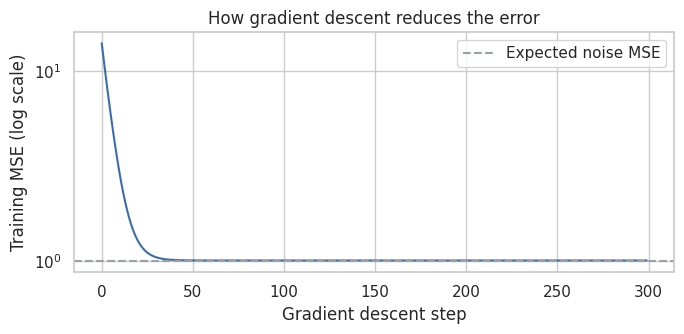

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.5))

ax.plot(gd.loss_history_, color=LR_C)
ax.axhline(
    1.0,
    ls="--",
    color=BASE_C,
    label="Expected noise MSE"
)

ax.set(
    yscale="log",
    xlabel="Gradient descent step",
    ylabel="Training MSE (log scale)",
    title="How gradient descent reduces the error"
)

ax.legend()
plt.tight_layout()
plt.show()


All three versions end up with similar weights, and they're close to the real ones. The small differences come from the noise I added, not from a bug in the code. Gradient descent levels off at an MSE of about 1.0, which is close to the noise variance. This makes sense because the model can't predict the random noise in new data.

## Part 2: Gradient boosting from scratch

Boosting works in rounds. It starts by predicting the average, and then each round does the same three things:

1. Look at the residuals, which are the parts the model is still getting wrong.
2. Fit a small decision tree to those residuals.
3. Add a fraction of that tree's predictions, controlled by the learning rate, to the model.

One small tree can't capture every pattern, but adding more trees lets the model learn more complicated shapes. With squared error, the residuals are proportional to the negative gradient of the loss, which is where the "gradient" in gradient boosting comes from.

I tested my version on a 1-D sine-shaped curve so I could see how the predictions change as more trees are added.

Max difference between my implementation and scikit-learn: 0.00e+00


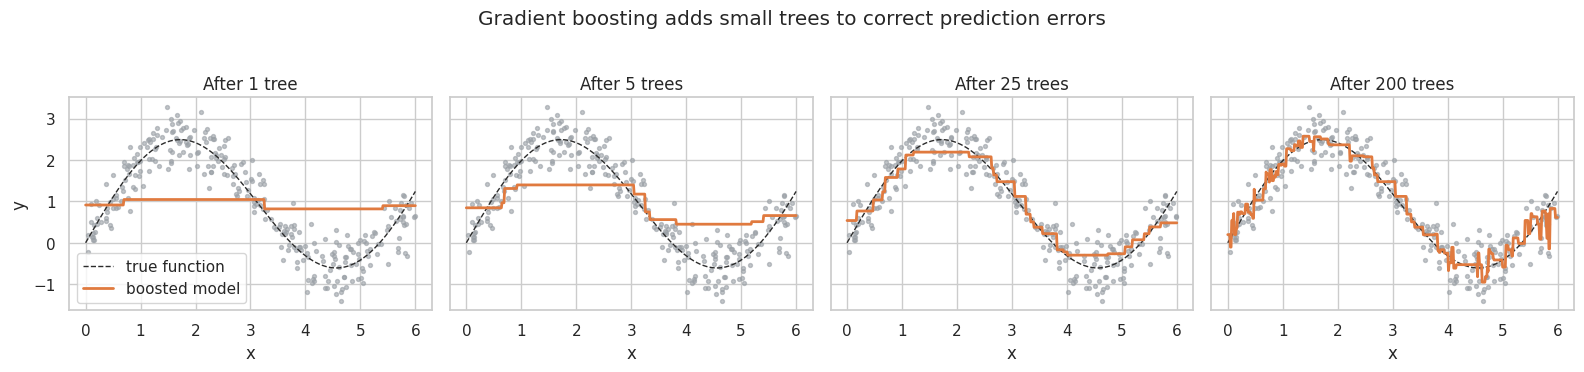

In [ ]:
class MyGradientBoosting:
    # Gradient boosting using small decision trees and squared error.

    def __init__(self, n_trees=100, lr=0.1, max_depth=2):
        self.n_trees, self.lr, self.max_depth = n_trees, lr, max_depth

    def fit(self, X, y):
        self.init_ = y.mean()
        pred = np.full(len(y), self.init_)
        self.trees_, self.train_loss_ = [], []

        for _ in range(self.n_trees):
            residuals = y - pred  # The errors the next tree tries to correct
            tree = DecisionTreeRegressor(max_depth=self.max_depth).fit(X, residuals)
            pred += self.lr * tree.predict(X)
            self.trees_.append(tree)
            self.train_loss_.append(np.mean((y - pred) ** 2))

        return self

    def predict(self, X, n_trees=None):
        # Use only the requested number of trees if specified
        trees = self.trees_ if n_trees is None else self.trees_[:n_trees]
        pred = np.full(X.shape[0], self.init_)

        for tree in trees:
            pred += self.lr * tree.predict(X)

        return pred


# Test gradient boosting on a curved function
rng = np.random.default_rng(1)
x = np.sort(rng.uniform(0, 6, 300))
X1 = x.reshape(-1, 1)

f = lambda x: np.sin(x) * 2 + 0.3 * x
y1 = f(x) + rng.normal(scale=0.4, size=len(x))

mine = MyGradientBoosting(n_trees=200, lr=0.1, max_depth=2).fit(X1, y1)
sk_gb = GradientBoostingRegressor(
    n_estimators=200, learning_rate=0.1, max_depth=2
).fit(X1, y1)

print(
    f"Max difference between my implementation and scikit-learn: "
    f"{np.abs(mine.predict(X1) - sk_gb.predict(X1)).max():.2e}"
)

grid = np.linspace(0, 6, 500).reshape(-1, 1)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)

for ax, k in zip(axes, [1, 5, 25, 200]):
    ax.scatter(x, y1, s=8, color=BASE_C, alpha=0.6)
    ax.plot(grid, f(grid), color=TRUE_C, lw=1, ls="--", label="true function")
    ax.plot(grid, mine.predict(grid, k), color=GB_C, lw=2, label="boosted model")
    ax.set(title=f"After {k} tree{'s' if k > 1 else ''}", xlabel="x")

axes[0].legend(loc="lower left")
axes[0].set_ylabel("y")
plt.suptitle(
    "Gradient boosting adds small trees to correct prediction errors",
    y=1.03
)
plt.tight_layout()
plt.show()

My version matches scikit-learn exactly. The max difference printed above is 0, so the two implementations make the same predictions.

The plots show how boosting works: each tree adds a few flat steps to the predictions. As more trees are added, the model gets closer to the curve. By 200 trees, it starts fitting some of the noise in individual data points, which creates those little wiggles at the bottom and right. This is a sign of overfitting. A smaller learning rate and early stopping can help reduce it.

The staircase shape shows why boosting can fit complicated patterns, but it can also be a weakness. Experiment 4 looks at this in more detail.

---

## Part 3: The experiments

Since I'm using simulated data, I know the true function and can compare how closely each model learns it. Every experiment uses the same setup:

1. The same two models without extra tuning: `LinearRegression()` and `HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05)`.
2. A held-out test set of 5,000 points, evaluated using RMSE.
3. Multiple runs with different random seeds. The charts show the average RMSE, with shaded bands representing ±1 standard deviation.

The noise has a standard deviation of 1, so an RMSE of 1.0 is the theoretical baseline when predicting the true function perfectly. Any extra error comes from the model not capturing the function exactly, though the test RMSE can vary around that baseline.

In [ ]:
# Four functions to test (5 input features, with x4 and x5 as noise)
TRUTHS = {
    "Linear":      lambda X: 3*X[:, 0] - 2*X[:, 1] + X[:, 2],
    "Curved":      lambda X: 2*np.sin(2*X[:, 0]) + X[:, 1]**2 + X[:, 2],
    "Interaction": lambda X: 2*X[:, 0]*X[:, 1] + X[:, 2],
    "Threshold":   lambda X: 3*(X[:, 0] > 0) + 2*(X[:, 1] > 0.5) + X[:, 2],
}

def simulate(truth, n, noise=1.0, n_features=5, seed=0, low=-2, high=2):
    rng = np.random.default_rng(seed)
    X = rng.uniform(low, high, size=(n, n_features))
    y = truth(X) + rng.normal(scale=noise, size=n)
    return X, y

def compare(truth, n_train, noise=1.0, n_features=5, seed=0):
    Xtr, ytr = simulate(truth, n_train, noise, n_features, seed)
    Xte, yte = simulate(truth, 5000, noise, n_features, seed + 10_000)

    out = {}
    models = [
        ("Linear regression", LinearRegression()),
        ("Gradient boosting", boosting()),
    ]

    for name, model in models:
        model.fit(Xtr, ytr)
        out[name] = rmse(yte, model.predict(Xte))

    out["Predict the mean"] = rmse(yte, np.full(len(yte), ytr.mean()))
    return out

def repeat(n_seeds=20, **kw):
    return pd.DataFrame([compare(seed=s, **kw) for s in range(n_seeds)])

### Experiment 1: Does the shape of the data matter?

For the first experiment, I kept the dataset size fixed at $n = 500$ and changed the underlying function. I tested four types of relationships: a straight line, a curve, an interaction between two features, and a step function.

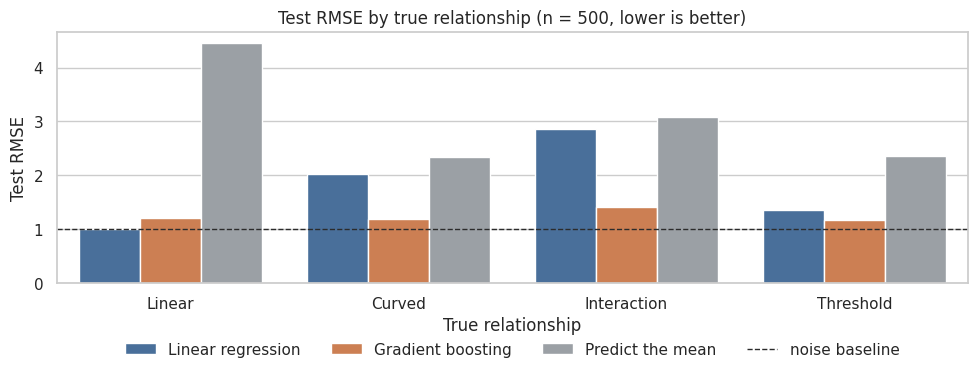

model,Linear regression,Gradient boosting,Predict the mean
truth,,,
Curved,2.015,1.191,2.345
Interaction,2.863,1.411,3.073
Linear,1.005,1.204,4.446
Threshold,1.361,1.159,2.348


In [ ]:
rows = []
for shape, fn in TRUTHS.items():
    r = repeat(truth=fn, n_train=500)
    for model in r.columns:
        rows.append({
            "truth": shape,
            "model": model,
            "rmse": r[model].mean(),
            "sd": r[model].std()
        })

exp1 = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(
    data=exp1, x="truth", y="rmse", hue="model", ax=ax,
    palette=[LR_C, GB_C, BASE_C],
    hue_order=["Linear regression", "Gradient boosting", "Predict the mean"]
)
ax.axhline(1.0, ls="--", color=TRUE_C, lw=1, label="noise baseline")
ax.set(
    title="Test RMSE by true relationship (n = 500, lower is better)",
    xlabel="True relationship",
    ylabel="Test RMSE"
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4, frameon=False)
plt.tight_layout()
plt.show()

exp1_table = exp1.pivot(
    index="truth", columns="model", values="rmse"
)[["Linear regression", "Gradient boosting", "Predict the mean"]]

exp1_table.round(3)

**What I found:** When the true relationship is a straight line, linear regression does really well, with an RMSE close to 1.0. Boosting does worse because it has to approximate the line using a series of steps.

When the data is curved or has an interaction, linear regression can't capture the shape on its own, so boosting performs much better. Boosting also wins on the step function, although the difference is smaller because linear regression can still capture some of the overall trend.

Neither model is always better. It depends on how well the model fits the underlying data. In Part 4, I come back to this idea and show how adding better features can help linear regression handle more complex relationships.

### Experiment 2: How much data does each model need?

Next, I varied the training set size from 20 to 5,000 examples. I tested both the straight-line function and the curved function to see how each model performs as it gets more data.

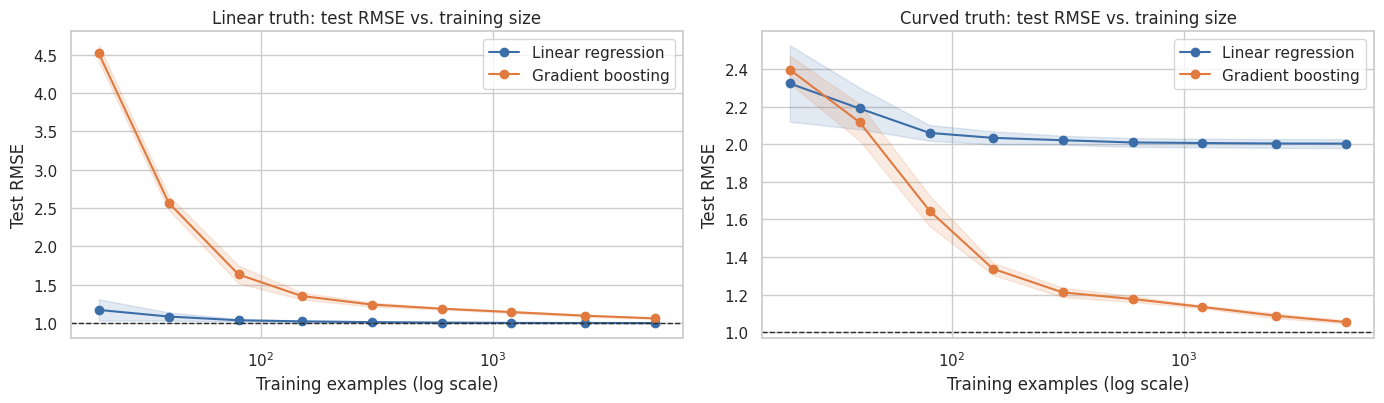

Curved truth: boosting first beats linear regression at n = 40


model,Gradient boosting,Linear regression
n,,
20,2.396,2.322
40,2.116,2.189
80,1.646,2.060
150,1.337,2.033
300,1.212,2.021
600,1.177,2.009
1200,1.135,2.006
2500,1.087,2.003
5000,1.054,2.003


In [ ]:
SIZES = [20, 40, 80, 150, 300, 600, 1200, 2500, 5000]
curves = []

for shape in ["Linear", "Curved"]:
    for n in SIZES:
        r = repeat(n_seeds=12, truth=TRUTHS[shape], n_train=n)

        for model in ["Linear regression", "Gradient boosting"]:
            curves.append({
                "truth": shape,
                "n": n,
                "model": model,
                "mean": r[model].mean(),
                "sd": r[model].std()
            })

curves = pd.DataFrame(curves)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

for ax, shape in zip(axes, ["Linear", "Curved"]):
    for model, col in [("Linear regression", LR_C), ("Gradient boosting", GB_C)]:
        d = curves[(curves.truth == shape) & (curves.model == model)]
        ax.plot(d.n, d["mean"], "o-", color=col, label=model)
        ax.fill_between(
            d.n, d["mean"] - d.sd, d["mean"] + d.sd,
            color=col, alpha=0.15
        )

    ax.axhline(1.0, ls="--", color=TRUE_C, lw=1)
    ax.set(
        xscale="log",
        title=f"{shape} truth: test RMSE vs. training size",
        xlabel="Training examples (log scale)",
        ylabel="Test RMSE"
    )
    ax.legend()

plt.tight_layout()
plt.show()

# Find the smallest training size where boosting beats linear regression
cv = curves[curves.truth == "Curved"].pivot(
    index="n", columns="model", values="mean"
)

better = cv[cv["Gradient boosting"] < cv["Linear regression"]]
crossover = better.index.min() if not better.empty else None

print(f"Curved truth: boosting first beats linear regression at n = {crossover}")
cv.round(3)

**What I found:** With the linear truth, linear regression gets close to the best possible RMSE with only about 40 examples. Boosting never catches up, even with 5,000 examples.

The curved truth is more interesting. Boosting needs enough data to learn the shape. With the smallest training sets, linear regression still does better, even though it can't fully represent the true function. This shows the bias-variance tradeoff: a simpler model can perform better with limited data because it's less likely to fit random noise.

### Experiment 3: What happens as the data gets noisier?

For this experiment, I used a function that's mostly linear but includes a small curve: $y = 2x_1 + x_2 + 0.5x_1^2$. I kept the training set at 300 examples and gradually increased the noise. To compare the results across noise levels, I divided each RMSE by the noise standard deviation, so a value near 1.0 means the model is performing close to the noise baseline.

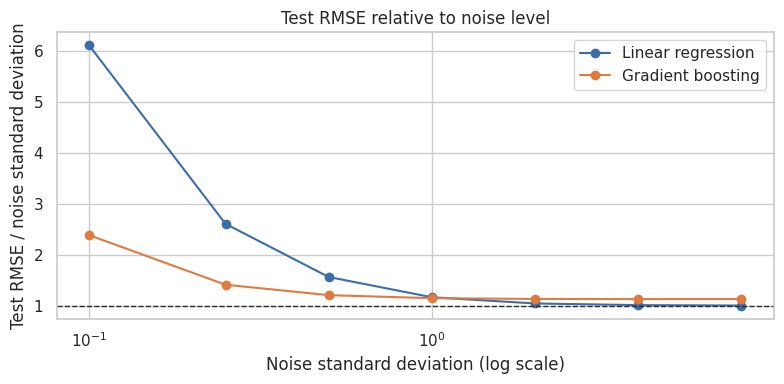

,Linear regression,Gradient boosting
noise_sd,,
0.10,6.120,2.393
0.25,2.615,1.419
0.50,1.570,1.214
1.00,1.173,1.154
2.00,1.051,1.139
4.00,1.018,1.136
8.00,1.010,1.137


In [ ]:
mostly_linear = lambda X: 2 * X[:, 0] + X[:, 1] + 0.5 * X[:, 0]**2

NOISES = [0.1, 0.25, 0.5, 1, 2, 4, 8]
noise_rows = []

for noise in NOISES:
    results = repeat(
        n_seeds=20,
        truth=mostly_linear,
        n_train=300,
        noise=noise
    )

    noise_rows.append({
        "noise_sd": noise,
        "Linear regression": results["Linear regression"].mean() / noise,
        "Gradient boosting": results["Gradient boosting"].mean() / noise
    })

noise_df = pd.DataFrame(noise_rows).set_index("noise_sd")

ax = noise_df.plot(
    marker="o",
    color=[LR_C, GB_C],
    figsize=(8, 4),
    logx=True
)

ax.axhline(1.0, ls="--", color=TRUE_C, lw=1)
ax.set(
    title="Test RMSE relative to noise level",
    xlabel="Noise standard deviation (log scale)",
    ylabel="Test RMSE / noise standard deviation"
)

plt.tight_layout()
plt.show()

noise_df.round(3)

**What I found:** When there's very little noise, the curve is easier to pick up, and gradient boosting does better at capturing it.

As the noise increases, the curve becomes harder to distinguish from random variation. Boosting can start fitting that noise, while the simpler linear model is less affected by it. In my results, the two lines cross between noise levels of 1 and 2. Beyond that point, linear regression performs better, even though it doesn't fully capture the true relationship.

### Experiment 4: Predicting outside the training data

For this experiment, I trained both models on data with $x$ values between 0 and 5, then tested their predictions on values extending to 10. The true relationship is a straight line, $y = 2x$.

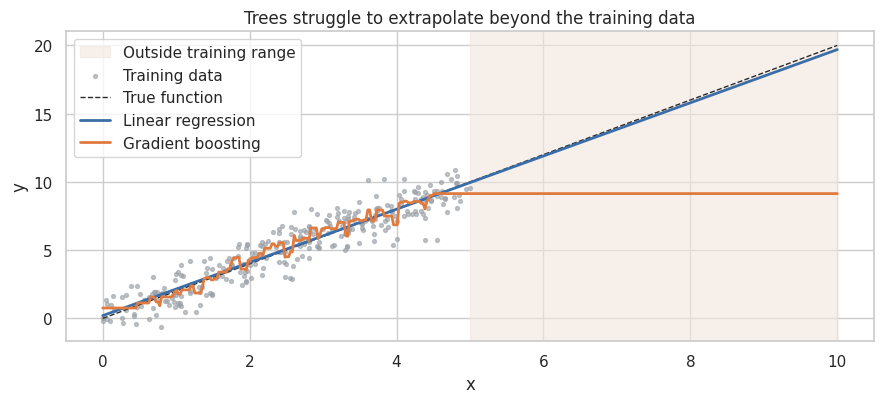

,"RMSE inside [0, 5]","RMSE outside (5, 10]"
Linear regression,0.10,0.19
Gradient boosting,0.44,6.54


In [ ]:
rng = np.random.default_rng(3)

# Generate training data from y = 2x with Gaussian noise
x_tr = rng.uniform(0, 5, 300)
y_tr = 2 * x_tr + rng.normal(scale=1, size=300)

# Test across the training range and beyond
x_te = np.linspace(0, 10, 400)
X_te = x_te.reshape(-1, 1)
X_tr = x_tr.reshape(-1, 1)

lr_fit = LinearRegression().fit(X_tr, y_tr)
gb_fit = boosting().fit(X_tr, y_tr)

fig, ax = plt.subplots(figsize=(9, 4.2))

ax.axvspan(
    5, 10, color="#f3e6dc", alpha=0.6,
    label="Outside training range"
)
ax.scatter(x_tr, y_tr, s=8, color=BASE_C, alpha=0.6, label="Training data")
ax.plot(x_te, 2 * x_te, "--", color=TRUE_C, lw=1, label="True function")
ax.plot(x_te, lr_fit.predict(X_te), color=LR_C, lw=2, label="Linear regression")
ax.plot(x_te, gb_fit.predict(X_te), color=GB_C, lw=2, label="Gradient boosting")

ax.set(
    title="Trees struggle to extrapolate beyond the training data",
    xlabel="x",
    ylabel="y"
)
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

# Compare errors inside and outside the training range
inside = x_te <= 5
outside = x_te > 5

extrap = pd.DataFrame({
    "RMSE inside [0, 5]": [
        rmse(2 * x_te[inside], model.predict(X_te[inside]))
        for model in (lr_fit, gb_fit)
    ],
    "RMSE outside (5, 10]": [
        rmse(2 * x_te[outside], model.predict(X_te[outside]))
        for model in (lr_fit, gb_fit)
    ]
}, index=["Linear regression", "Gradient boosting"])

extrap.round(2)

**What I found:** This was one of the biggest differences between the models in my experiments. A decision tree predicts based on the regions it learned from the training data. Beyond the training range, its predictions stay flat instead of following the true line. Linear regression continues the trend because it learns a slope. In my results, boosting's error outside the training range was more than 30 times higher.

This matters when a model needs to predict beyond the data it was trained on, such as forecasting growth or estimating prices during changing market conditions. A model that fits past data well may still struggle when asked to extrapolate.

### Experiment 5: Adding useless features

Real datasets often contain columns that have little or no predictive value. For this experiment, I kept the same linear relationship with three useful features and added more columns of random noise. I kept the training set at 300 rows to see how each model handled the extra features.

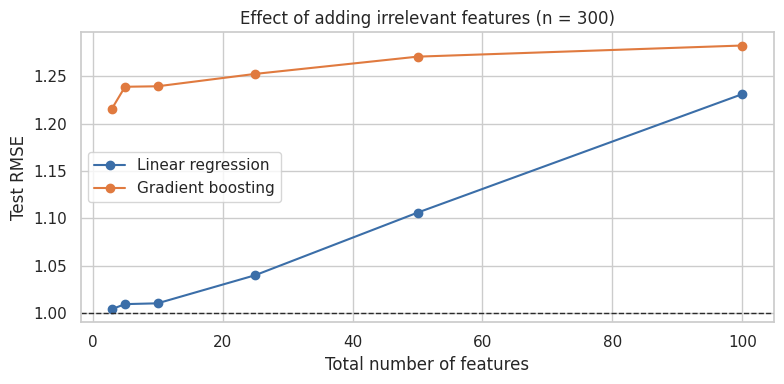

,Linear regression,Gradient boosting
features,,
3,1.004,1.216
5,1.010,1.239
10,1.010,1.240
25,1.040,1.253
50,1.106,1.271
100,1.231,1.283


In [ ]:
FEATS = [3, 5, 10, 25, 50, 100]
irr_rows = []

for n_features in FEATS:
    results = repeat(
        n_seeds=12,
        truth=TRUTHS["Linear"],
        n_train=300,
        n_features=n_features
    )

    irr_rows.append({
        "features": n_features,
        "Linear regression": results["Linear regression"].mean(),
        "Gradient boosting": results["Gradient boosting"].mean()
    })

irr = pd.DataFrame(irr_rows).set_index("features")

ax = irr.plot(
    marker="o",
    color=[LR_C, GB_C],
    figsize=(8, 4)
)

ax.axhline(1.0, ls="--", color=TRUE_C, lw=1)
ax.set(
    title="Effect of adding irrelevant features (n = 300)",
    xlabel="Total number of features",
    ylabel="Test RMSE"
)

plt.tight_layout()
plt.show()

irr.round(3)

**What I found:** Linear regression still performs better because the true relationship is linear, but its advantage gets smaller as I add more irrelevant features. With only 300 training examples, adding more columns makes it harder to estimate the useful coefficients accurately.

Gradient boosting's performance changes much less in this experiment. Trees can ignore features that don't help their predictions, although they aren't guaranteed to ignore every irrelevant feature. For linear regression, regularization methods like Ridge and Lasso can help by shrinking coefficients and reducing the effect of noise.

---

## Part 4: Does any of this hold up on real data?

The simulations let me control the data, so I wanted to see whether the same patterns show up on real datasets. I chose two datasets with different characteristics:

| Dataset | Rows | What I'm predicting | What I expect |
|---|---:|---|---|
| Diabetes (from scikit-learn) | 442 | Disease progression after one year | The small sample and noisy target may make linear regression competitive |
| Diamonds (from seaborn) | 53,940 | Price in dollars | The larger dataset and nonlinear relationship between features and price may favor boosting, unless I improve linear regression with better features |

I evaluated both models using 5-fold cross-validation and compared their RMSE against a baseline that always predicts the training-set mean.

In [ ]:
def cv_score(model, X, y, folds=5):
    cv = KFold(n_splits=folds, shuffle=True, random_state=0)

    results = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=("neg_root_mean_squared_error", "r2")
    )

    return {
        "RMSE": -results["test_neg_root_mean_squared_error"].mean(),
        "R²": results["test_r2"].mean()
    }


# Diabetes dataset
Xd, yd = load_diabetes(return_X_y=True, as_frame=True)

diabetes = pd.DataFrame({
    "Predict the mean": cv_score(DummyRegressor(), Xd, yd),
    "Linear regression": cv_score(LinearRegression(), Xd, yd),
    "Gradient boosting": cv_score(boosting(), Xd, yd)
}).T

diabetes.round(3)

,RMSE,R²
Predict the mean,76.930,-0.001
Linear regression,54.527,0.489
Gradient boosting,60.001,0.378


In [ ]:
# Diamonds dataset
dia = sns.load_dataset("diamonds")

cat_cols = ["cut", "color", "clarity"]
num_cols = ["carat", "depth", "table", "x", "y", "z"]

Xm = dia[cat_cols + num_cols]
ym = dia["price"]


def encoder(num_transform=None):
    """Encode categorical columns and optionally transform numeric columns."""
    num = "passthrough" if num_transform is None else num_transform

    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", num, num_cols)
    ])


from sklearn.preprocessing import FunctionTransformer

log_carat = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("log_carat", FunctionTransformer(np.log, feature_names_out="one-to-one"), ["carat"])
])

models = {
    "Predict the mean": DummyRegressor(),

    "Linear regression (raw features)": make_pipeline(
        encoder(),
        LinearRegression()
    ),

    # Predict log(price) using log(carat) and the categorical grades.
    # This lets the model capture a nonlinear relationship between carat and price.
    "Linear regression (log-log features)": TransformedTargetRegressor(
        regressor=make_pipeline(log_carat, LinearRegression()),
        func=np.log,
        inverse_func=np.exp
    ),

    "Gradient boosting": make_pipeline(
        encoder(),
        boosting()
    )
}

diamonds = pd.DataFrame({
    name: cv_score(model, Xm, ym)
    for name, model in models.items()
}).T

diamonds.round(3)

,RMSE,R²
Predict the mean,3989.428,-0.000
Linear regression (raw features),1131.256,0.920
Linear regression (log-log features),800.277,0.960
Gradient boosting,546.521,0.981


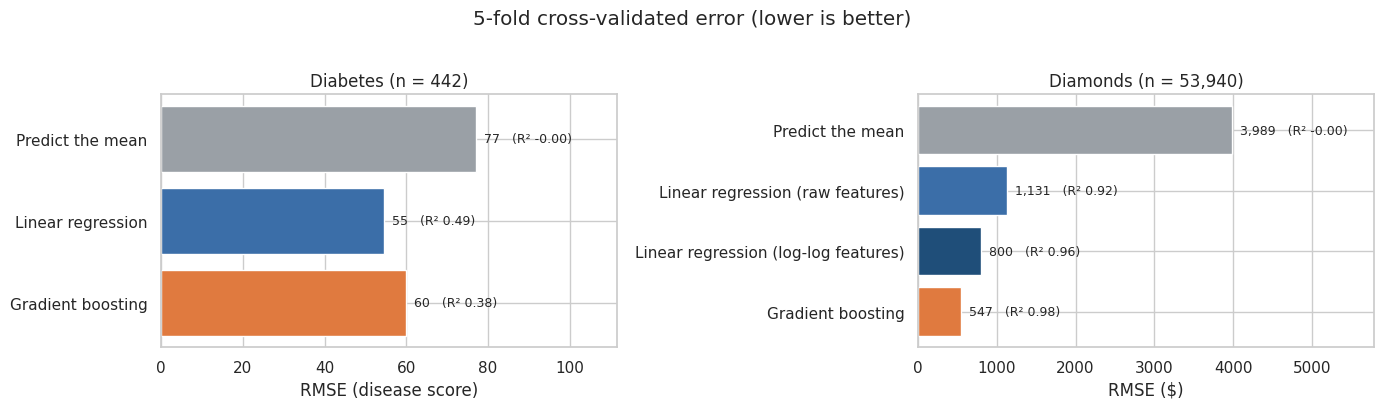

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

colors = {
    "Predict the mean": BASE_C,
    "Linear regression": LR_C,
    "Linear regression (raw features)": LR_C,
    "Linear regression (log-log features)": "#1f4e79",
    "Gradient boosting": GB_C
}

datasets = [
    ("Diabetes (n = 442)", diabetes, "RMSE (disease score)"),
    ("Diamonds (n = 53,940)", diamonds, "RMSE ($)")
]

for ax, (title, df, unit) in zip(axes, datasets):
    ax.barh(
        df.index,
        df["RMSE"],
        color=[colors[name] for name in df.index]
    )

    for i, (rmse_value, r2) in enumerate(zip(df["RMSE"], df["R²"])):
        ax.text(
            rmse_value, i,
            f"  {rmse_value:,.0f}   (R² {r2:.2f})",
            va="center",
            fontsize=9
        )

    ax.set(
        title=title,
        xlabel=unit,
        xlim=(0, df["RMSE"].max() * 1.45)
    )
    ax.invert_yaxis()

plt.suptitle("5-fold cross-validated error (lower is better)", y=1.02)
plt.tight_layout()
plt.show()

**Diabetes:** This matched what I saw in the earlier experiments. On this small, noisy dataset, linear regression performed better than gradient boosting. It's also easier to interpret.

**Diamonds:** Linear regression struggled with the raw features because price doesn't increase linearly with carat. A diamond that's twice the carat weight can cost much more than twice as much. Gradient boosting handles this curved relationship without needing me to specify its shape.

To improve linear regression, I took the log of both price and carat. This makes the relationship closer to a straight line:

$\log(\text{price}) \approx k\log(\text{carat}) + \text{grade effects}$

With this change, linear regression closed more than half the gap to boosting while using fewer features than the raw version. This connects back to Experiment 1: the features we give a model can make a big difference in how well it performs.

In [ ]:
# Interpretability: what the log-log model's coefficients mean
loglin = models["Linear regression (log-log features)"].fit(Xm, ym)

names = loglin.regressor_[0].get_feature_names_out()
coefs = pd.Series(loglin.regressor_[-1].coef_, index=names)

selected = [
    name for name in names
    if name.startswith("cat__clarity") or name.startswith("log_carat")
]

print("Selected coefficients (effects on log(price)):")
print(coefs[selected].round(3).to_string())

k = coefs[[name for name in names if name.startswith("log_carat")][0]]

clarity_ratio = np.exp(
    coefs["cat__clarity_IF"] - coefs["cat__clarity_I1"]
)

print(
    f"\nIF vs. I1 clarity: about {clarity_ratio:.1f}x the price, "
    "holding carat, cut and color constant."
)

print(
    f"Carat elasticity: a 10% increase in carat is associated with "
    f"about {(1.1**k - 1) * 100:.0f}% higher price, "
    "holding the other features constant."
)

Selected coefficients (effects on log(price)):
cat__clarity_I1     -0.707
cat__clarity_IF      0.407
cat__clarity_SI1    -0.114
cat__clarity_SI2    -0.279
cat__clarity_VS1     0.105
cat__clarity_VS2     0.035
cat__clarity_VVS1    0.312
cat__clarity_VVS2    0.240
log_carat__carat     1.884

IF vs. I1 clarity: about 3.0x the price, holding carat, cut and color constant.
Carat elasticity: a 10% increase in carat is associated with about 20% higher price, holding the other features constant.


Another thing I like about the log-log model is that the coefficients are easier to interpret. The carat coefficient tells me how much the predicted price changes, in percentage terms, when carat weight increases by 1%. The difference between two clarity coefficients tells me the price difference between those grades, holding the other features constant.

With gradient boosting, it's harder to get this kind of direct explanation. Tools like SHAP can help explain how individual features influence its predictions, but the explanations aren't as straightforward as reading coefficients from a linear model.

---

## Part 5: Summary

In [ ]:
lin_truth = exp1_table.loc["Linear"]
curv_truth = exp1_table.loc["Curved"]

print("KEY RESULTS")
print("-" * 60)

print(
    f"Linear truth (n=500): "
    f"linear RMSE = {lin_truth['Linear regression']:.2f}, "
    f"boosting RMSE = {lin_truth['Gradient boosting']:.2f}"
)

print(
    f"Curved truth (n=500): "
    f"linear RMSE = {curv_truth['Linear regression']:.2f}, "
    f"boosting RMSE = {curv_truth['Gradient boosting']:.2f}"
)

print(
    f"Curved truth: boosting starts to outperform linear regression "
    f"at about n = {crossover}"
)

print(
    f"Extrapolation: boosting's RMSE outside the training range is "
    f"{extrap.iloc[1, 1] / extrap.iloc[0, 1]:.0f}x linear regression's"
)

print(
    f"Diabetes: linear regression R² = "
    f"{diabetes.loc['Linear regression', 'R²']:.3f}, "
    f"boosting R² = {diabetes.loc['Gradient boosting', 'R²']:.3f}"
)

print(
    f"Irrelevant features: linear regression's RMSE advantage changes "
    f"from {irr.iloc[0, 1] - irr.iloc[0, 0]:.2f} to "
    f"{irr.iloc[-1, 1] - irr.iloc[-1, 0]:.2f} "
    f"as the feature count increases from 3 to 100"
)

print(
    f"Diamonds: raw linear R² = {diamonds.iloc[1]['R²']:.3f}, "
    f"log-log linear R² = {diamonds.iloc[2]['R²']:.3f}, "
    f"boosting R² = {diamonds.iloc[3]['R²']:.3f}"
)

KEY RESULTS
------------------------------------------------------------
Linear truth (n=500): linear RMSE = 1.00, boosting RMSE = 1.20
Curved truth (n=500): linear RMSE = 2.02, boosting RMSE = 1.19
Curved truth: boosting starts to outperform linear regression at about n = 40
Extrapolation: boosting's RMSE outside the training range is 34x linear regression's
Diabetes: linear regression R² = 0.489, boosting R² = 0.378
Irrelevant features: linear regression's RMSE advantage changes from 0.21 to 0.05 as the feature count increases from 3 to 100
Diamonds: raw linear R² = 0.920, log-log linear R² = 0.960, boosting R² = 0.981


Here's how I'd choose between the two based on what I found:

| Situation | What I'd try first | Why (where I saw it) |
|---|---|---|
| The relationship is roughly linear, or a transform like a log makes it closer to linear | Linear regression | It can fit the relationship directly instead of approximating it with tree splits (Exp. 1, Diamonds) |
| Small dataset (a few hundred rows) | Linear regression | A simpler model can do better when there's not enough data to learn a more complex pattern (Exp. 2, Diabetes) |
| Very noisy target | Linear regression | In my experiment, boosting became less effective as the noise increased (Exp. 3) |
| Need to predict outside the training range | Linear regression | It can extend a learned trend beyond the training data, while tree-based predictions tend to flatten out (Exp. 4) |
| Need to interpret feature effects | Linear regression | Its coefficients are easier to interpret directly (Diamonds) |
| Curves, cutoffs, or interactions that are hard to specify by hand | Gradient boosting | It can learn nonlinear patterns and interactions from the data (Exp. 1) |
| Lots of data with complicated patterns | Gradient boosting | More data can help it learn patterns that a simple linear model misses (Exp. 2, Diamonds) |

My main takeaway is that gradient boosting is a strong option for complicated tabular data, but it isn't automatically better. Going forward, I'll start with a linear model and use it as a baseline. If its performance is close to boosting, the simpler model may be the better choice because it's easier to interpret and can extrapolate beyond the training range.

### What I'd do next

- I used fixed settings for both models. Tuning boosting and trying Ridge or Lasso for linear regression could change the results, so I'd like to compare them using cross-validated tuning.
- My simulated features are independent and uniformly distributed. Real datasets can have correlated features, outliers and missing values, so I'd like to test how those affect each model.
- I'd also like to add more models to the comparison, including Ridge, Lasso, random forests and a small neural network.